In [7]:
# The following code will only execute
# successfully when compression is complete

import kagglehub

# Download latest version
path = kagglehub.dataset_download("shaikakram67/deepfake")

print("Path to dataset files:", path)

# Define the directory paths for the training, validation, and test datasets using the correct kagglehub path
train_dir = f'{path}/Dataset/Train'
val_dir   = f'{path}/Dataset/Validation'
test_dir  = f'{path}/Dataset/Test'

Path to dataset files: /kaggle/input/datasets/shaikakram67/deepfake


In [8]:
import os
import random
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import timm

# Print the installed PyTorch version to verify the environment setup
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("⚠️ GPU is not enabled. Go to Runtime → Change runtime type → GPU")

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
Using device: cuda


In [9]:
import os

print("Train exists:", os.path.exists(train_dir))
print("Validation exists:", os.path.exists(val_dir))
print("Test exists:", os.path.exists(test_dir))

# Ensure the directories actually exist before listing them
if os.path.exists(train_dir):
    classes = os.listdir(train_dir)
    num_classes = len(classes)
    print(f'Number of Classes: {num_classes}')
    print("Train folders:", os.listdir(train_dir))
    print("Validation folders:", os.listdir(val_dir))
    print("Test folders:", os.listdir(test_dir))
else:
    print("⚠️ Dataset directories do not exist. Please check dataset path correctness.")

Train exists: True
Validation exists: True
Test exists: True
Number of Classes: 2
Train folders: ['Fake', 'Real']
Validation folders: ['Fake', 'Real']
Test folders: ['Fake', 'Real']


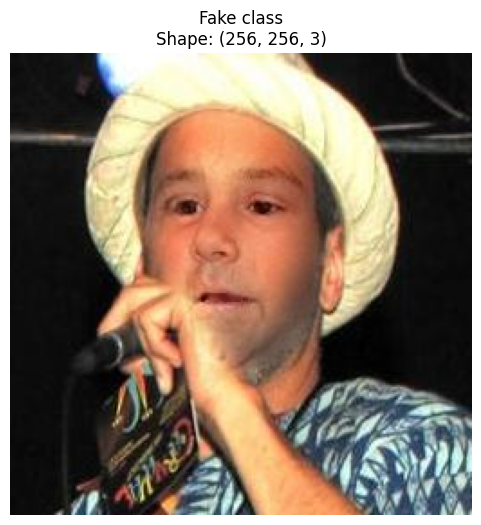

In [84]:
random_class = random.choice(classes)
random_class_path = os.path.join(train_dir, random_class)
image_files = os.listdir(random_class_path)
random_img_name = random.choice(image_files)
random_img_path = os.path.join(random_class_path, random_img_name)

random_img = plt.imread(random_img_path)

plt.figure(figsize=(6, 6))
plt.imshow(random_img)
plt.title(f'{random_class} class\nShape: {random_img.shape}')
plt.axis('off')
plt.show()

In [11]:
# =========================
# DATA PIPELINE WITH INTEGRATED BILATERAL FILTERING
# =========================
import os
import cv2
import numpy as np
import torch
from PIL import Image
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

IMG_SIZE = 256
BATCH_SIZE = 16
NUM_WORKERS = min(4, os.cpu_count() or 2) if torch.cuda.is_available() else 0

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# Parameters must be reported in the paper and held fixed for the main experiment.
BILATERAL_DIAMETER = 9
BILATERAL_SIGMA_COLOR = 100
BILATERAL_SIGMA_SPACE = 100
USE_BILATERAL_FILTER = True

class BilateralFilter:
    """Apply OpenCV bilateral filtering to RGB PIL images before tensor conversion."""
    def __init__(self, enabled=True, diameter=9, sigma_color=100, sigma_space=100):
        self.enabled = enabled
        self.diameter = diameter
        self.sigma_color = sigma_color
        self.sigma_space = sigma_space

    def __call__(self, image):
        if not self.enabled:
            return image
        rgb = np.asarray(image.convert("RGB"))
        filtered = cv2.bilateralFilter(
            rgb, d=self.diameter,
            sigmaColor=self.sigma_color,
            sigmaSpace=self.sigma_space
        )
        return Image.fromarray(filtered)

bilateral = BilateralFilter(
    enabled=USE_BILATERAL_FILTER,
    diameter=BILATERAL_DIAMETER,
    sigma_color=BILATERAL_SIGMA_COLOR,
    sigma_space=BILATERAL_SIGMA_SPACE
)

train_transform = transforms.Compose([
    bilateral,
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.9, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.1, hue=0.03),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    transforms.RandomErasing(p=0.15, scale=(0.02, 0.12), value=0)
])

val_test_transform = transforms.Compose([
    bilateral,
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

train_dataset = datasets.ImageFolder(train_dir, transform=train_transform)
val_dataset   = datasets.ImageFolder(val_dir, transform=val_test_transform)
test_dataset  = datasets.ImageFolder(test_dir, transform=val_test_transform)

assert train_dataset.classes == val_dataset.classes == test_dataset.classes, \
    "Train/Validation/Test class order must be identical."

num_classes = len(train_dataset.classes)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())

print("Classes:", train_dataset.classes)
print("Image size:", IMG_SIZE, "| batch size:", BATCH_SIZE)
print("Bilateral filter:", USE_BILATERAL_FILTER,
      "| d/sigmaColor/sigmaSpace:", BILATERAL_DIAMETER,
      BILATERAL_SIGMA_COLOR, BILATERAL_SIGMA_SPACE)
print("Train/validation/test:", len(train_dataset), len(val_dataset), len(test_dataset))


Classes: ['Fake', 'Real']
Image size: 256 | batch size: 16
Bilateral filter: True | d/sigmaColor/sigmaSpace: 9 100 100
Train/validation/test: 9600 1200 1200


In [12]:
# ============================================================
# DATA LEAKAGE AUDIT: EXACT + PERCEPTUAL DUPLICATES
# Run this before training. It writes a CSV of cross-split matches.
# ============================================================
import os, hashlib, itertools, csv
from collections import defaultdict
from PIL import Image
import numpy as np

SPLIT_DIRS = {"train": train_dir, "validation": val_dir, "test": test_dir}
AUDIT_CSV = "leakage_audit_matches.csv"

def image_paths_by_split(split_dirs):
    out = {}
    for split, root in split_dirs.items():
        files = []
        for cls in sorted(os.listdir(root)):
            class_dir = os.path.join(root, cls)
            if not os.path.isdir(class_dir):
                continue
            for name in sorted(os.listdir(class_dir)):
                path = os.path.join(class_dir, name)
                if os.path.isfile(path):
                    files.append((path, cls))
        out[split] = files
    return out

def sha256_file(path, chunk_size=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()

def dhash_hex(path, hash_size=8):
    # Dependency-light perceptual hash; resize to 9x8 grayscale and compare neighbours.
    with Image.open(path) as im:
        im = im.convert("L").resize((hash_size + 1, hash_size), Image.Resampling.LANCZOS)
        a = np.asarray(im, dtype=np.int16)
    bits = (a[:, 1:] > a[:, :-1]).flatten()
    value = 0
    for bit in bits:
        value = (value << 1) | int(bit)
    return value

def hamming(a, b):
    return (a ^ b).bit_count()

split_files = image_paths_by_split(SPLIT_DIRS)
print({k: len(v) for k, v in split_files.items()})

# Exact duplicate audit using file-content hashes.
exact_index = defaultdict(list)
for split, entries in split_files.items():
    for path, label in entries:
        try:
            exact_index[sha256_file(path)].append((split, path, label))
        except Exception as exc:
            print("Unreadable file:", path, repr(exc))

exact_cross = []
for digest, items in exact_index.items():
    split_names = {x[0] for x in items}
    if len(split_names) > 1:
        exact_cross.append((digest, items))

print("Cross-split exact duplicate groups:", len(exact_cross))

# Perceptual duplicate candidates. Hamming threshold 6 is a screening threshold,
# not proof; manually inspect matches and consider a stricter/looser threshold.
hash_index = defaultdict(list)
for split, entries in split_files.items():
    for path, label in entries:
        try:
            hash_index[split].append((dhash_hex(path), path, label))
        except Exception as exc:
            print("Hash failed:", path, repr(exc))

near_matches = []
splits = list(hash_index)
for split_a, split_b in itertools.combinations(splits, 2):
    # Pairwise comparisons are performed only across splits.
    # For very large datasets, use a BK-tree/FAISS index to reduce this cost.
    for ha, pa, la in hash_index[split_a]:
        for hb, pb, lb in hash_index[split_b]:
            dist = hamming(ha, hb)
            if dist <= 6:
                near_matches.append((split_a, pa, la, split_b, pb, lb, dist))

with open(AUDIT_CSV, "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["split_a","path_a","label_a","split_b","path_b","label_b","dhash_hamming"])
    for _, items in exact_cross:
        for a, b in itertools.combinations(items, 2):
            if a[0] != b[0]:
                writer.writerow([a[0],a[1],a[2],b[0],b[1],b[2],"EXACT"])
    writer.writerows(near_matches)

print("Cross-split near-duplicate pairs (dHash distance <= 6):", len(near_matches))
print("Audit report:", AUDIT_CSV)
print("IMPORTANT: dHash matches are candidates, not confirmed duplicates.")


{'train': 9600, 'validation': 1200, 'test': 1200}
Cross-split exact duplicate groups: 0
Cross-split near-duplicate pairs (dHash distance <= 6): 29
Audit report: leakage_audit_matches.csv
IMPORTANT: dHash matches are candidates, not confirmed duplicates.


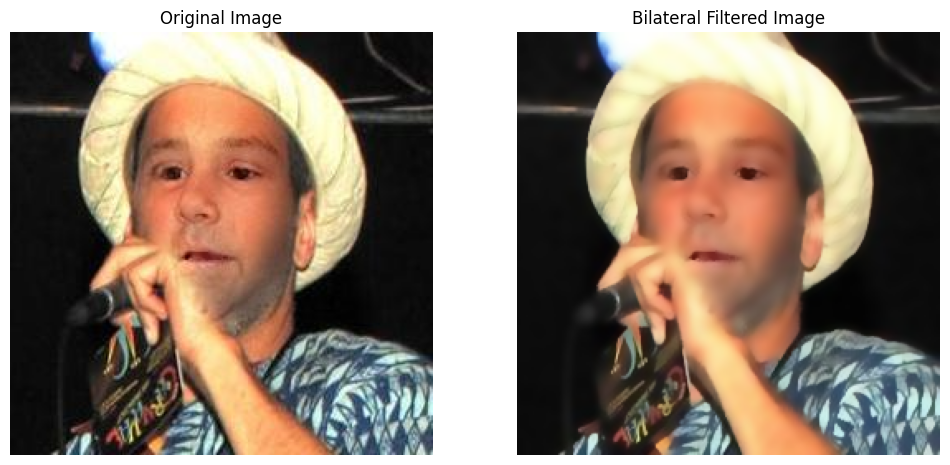

In [85]:
filtered_img = cv2.bilateralFilter(random_img, d=9, sigmaColor=100, sigmaSpace=100)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(random_img)
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(filtered_img)
plt.title('Bilateral Filtered Image')
plt.axis('off')

plt.show()

## HSViT: token-level bidirectional cross-attention

The SwinV2 and ViT branches expose token/feature sequences. Each stream is projected to a common embedding dimension. Swin queries ViT keys/values and ViT queries Swin keys/values; both updates use residual connections and layer normalisation. The pooled streams are concatenated only after cross-attention. Bilateral filtering is applied in the image transform pipeline before tensor normalisation.

Run the leakage-audit cell before training. Do not use the test split for model selection.


In [14]:
# =========================
# PRETRAINED SWINV2 + VIT TOKEN EXTRACTORS
# =========================
import timm
import torch
import torch.nn as nn

# global_pool='' preserves token/spatial sequences for cross-attention.
swin_model = timm.create_model(
    "swinv2_tiny_window16_256", pretrained=True, num_classes=0, global_pool=""
)
vit_model = timm.create_model(
    "vit_base_patch16_224", pretrained=True, num_classes=0,
    global_pool="", img_size=IMG_SIZE
)

print("SwinV2 feature dimension:", swin_model.num_features)
print("ViT feature dimension:", vit_model.num_features)


model.safetensors: reconstructing file:   0%|          |  0.00B /  119MB            

model.safetensors: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

SwinV2 feature dimension: 768
ViT feature dimension: 768


In [15]:
# =========================
# TRUE BIDIRECTIONAL CROSS-ATTENTION HSViT
# =========================
import torch
import torch.nn as nn

class BidirectionalCrossAttention(nn.Module):
    def __init__(self, swin_dim, vit_dim, embed_dim=384, num_heads=6, dropout=0.1):
        super().__init__()
        assert embed_dim % num_heads == 0
        self.swin_proj = nn.Linear(swin_dim, embed_dim)
        self.vit_proj = nn.Linear(vit_dim, embed_dim)
        self.swin_queries_vit = nn.MultiheadAttention(
            embed_dim, num_heads, dropout=dropout, batch_first=True
        )
        self.vit_queries_swin = nn.MultiheadAttention(
            embed_dim, num_heads, dropout=dropout, batch_first=True
        )
        self.swin_norm = nn.LayerNorm(embed_dim)
        self.vit_norm = nn.LayerNorm(embed_dim)
        self.dropout = nn.Dropout(dropout)

    @staticmethod
    def to_tokens(features, expected_dim):
        # Supports timm outputs B,N,C, B,H,W,C, and B,C,H,W.
        if features.ndim == 4:
            if features.shape[-1] == expected_dim:       # NHWC
                features = features.reshape(features.shape[0], -1, expected_dim)
            elif features.shape[1] == expected_dim:      # NCHW
                features = features.flatten(2).transpose(1, 2)
            else:
                raise RuntimeError(f"Cannot infer channel axis from {tuple(features.shape)}")
        elif features.ndim == 3:
            if features.shape[-1] != expected_dim:
                raise RuntimeError(f"Expected last token dimension {expected_dim}, got {tuple(features.shape)}")
        elif features.ndim == 2:
            features = features.unsqueeze(1)
        else:
            raise RuntimeError(f"Unsupported backbone output shape: {tuple(features.shape)}")
        return features

    def forward(self, swin_features, vit_features):
        s = self.to_tokens(swin_features, self.swin_proj.in_features)
        v = self.to_tokens(vit_features, self.vit_proj.in_features)
        s = self.swin_proj(s)
        v = self.vit_proj(v)

        # Direction 1: Swin queries, ViT supplies keys and values.
        s_context, _ = self.swin_queries_vit(query=s, key=v, value=v, need_weights=False)
        # Direction 2: ViT queries, Swin supplies keys and values.
        v_context, _ = self.vit_queries_swin(query=v, key=s, value=s, need_weights=False)

        s_refined = self.swin_norm(s + self.dropout(s_context))
        v_refined = self.vit_norm(v + self.dropout(v_context))
        return s_refined.mean(dim=1), v_refined.mean(dim=1)

class HybridSwinViT(nn.Module):
    def __init__(self, swin_model, vit_model, num_classes,
                 fusion_dim=384, num_heads=6, dropout=0.3):
        super().__init__()
        self.swin = swin_model
        self.vit = vit_model
        self.fusion = BidirectionalCrossAttention(
            swin_model.num_features, vit_model.num_features,
            embed_dim=fusion_dim, num_heads=num_heads, dropout=dropout
        )
        self.classifier = nn.Sequential(
            nn.LayerNorm(2 * fusion_dim),
            nn.Linear(2 * fusion_dim, 512),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(512, 128),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        swin_tokens = self.swin.forward_features(x)
        vit_tokens = self.vit.forward_features(x)
        swin_vec, vit_vec = self.fusion(swin_tokens, vit_tokens)
        fused = torch.cat([swin_vec, vit_vec], dim=1)
        return self.classifier(fused)

hybrid_model = HybridSwinViT(
    swin_model, vit_model, num_classes=num_classes,
    fusion_dim=384, num_heads=6, dropout=0.3
).to(device)

# Smoke test: catches backbone-layout or attention-shape mismatches before training.
hybrid_model.eval()
with torch.no_grad():
    sample_images, _ = next(iter(train_loader))
    sample_logits = hybrid_model(sample_images[:2].to(device))
assert sample_logits.shape == (2, num_classes), sample_logits.shape
print("Bidirectional cross-attention HSViT ready:", tuple(sample_logits.shape))


Bidirectional cross-attention HSViT ready: (2, 2)


In [16]:
hybrid_model.eval()
images, labels = next(iter(train_loader))
images = images.to(device)

with torch.no_grad():
    print(f"Hybrid classifier first layer weight shape: {hybrid_model.classifier[0].weight.shape}")
    output = hybrid_model(images)

print("Input shape:", images.shape)
print("Output shape:", output.shape)

Hybrid classifier first layer weight shape: torch.Size([768])
Input shape: torch.Size([16, 3, 256, 256])
Output shape: torch.Size([16, 2])


In [17]:
# =========================
# LOSS, OPTIMIZER, SCHEDULER & EMA
# =========================
import torch
import torch.nn as nn
import copy
import numpy as np

# Mild label smoothing improves calibration and reduces over-confident predictions
criterion = nn.CrossEntropyLoss(label_smoothing=0.08)

# Group parameters to exclude 1D biases and Norm layers from weight decay
def build_optimizer_groups(model, backbone_lr=2e-5, head_lr=2e-4, weight_decay=1e-4):
    decay_backbone, no_decay_backbone = [], []
    decay_head, no_decay_head = [], []

    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        is_head = "classifier" in name
        if param.ndim <= 1 or name.endswith(".bias") or "norm" in name.lower():
            (no_decay_head if is_head else no_decay_backbone).append(param)
        else:
            (decay_head if is_head else decay_backbone).append(param)

    return [
        {"params": decay_backbone, "lr": backbone_lr, "weight_decay": weight_decay},
        {"params": no_decay_backbone, "lr": backbone_lr, "weight_decay": 0.0},
        {"params": decay_head, "lr": head_lr, "weight_decay": weight_decay},
        {"params": no_decay_head, "lr": head_lr, "weight_decay": 0.0}
    ]

param_groups = build_optimizer_groups(hybrid_model, backbone_lr=2e-5, head_lr=2e-4, weight_decay=1e-4)
optimizer = torch.optim.AdamW(param_groups)

num_epochs = 50 # Optimized for high accuracy with modern backbones
warmup_epochs = 2

# Warmup + Cosine Annealing Learning Rate Scheduler
def lr_lambda(epoch):
    if epoch < warmup_epochs:
        return float(epoch + 1) / float(warmup_epochs)
    progress = float(epoch - warmup_epochs) / float(max(1, num_epochs - warmup_epochs))
    return max(0.05, 0.5 * (1.0 + np.cos(np.pi * progress)))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lr_lambda)

# Exponential Moving Average (EMA) class for smoother validation loss
class ModelEMA:
    def __init__(self, model, decay=0.999):
        self.module = copy.deepcopy(model).eval()
        self.decay = decay

    def update(self, model):
        with torch.no_grad():
            for ema_param, param in zip(self.module.parameters(), model.parameters()):
                ema_param.data.mul_(self.decay).add_(param.data, alpha=1.0 - self.decay)

ema = ModelEMA(hybrid_model, decay=0.999)
scaler = torch.amp.GradScaler("cuda", enabled=torch.cuda.is_available())

print("Optimizer with weight-decay splitting, Warmup+Cosine scheduler, EMA, and AMP are ready.")

Optimizer with weight-decay splitting, Warmup+Cosine scheduler, EMA, and AMP are ready.


In [18]:
# =========================
# ENHANCED HYBRID TRAINING
# =========================
import copy
import numpy as np
import torch

history_hybrid = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": [],
    "lr": []
}

best_val_acc = -1.0
best_val_loss = float("inf")
best_epoch = -1

epochs_without_improvement = 0
best_state = copy.deepcopy(hybrid_model.state_dict())
grad_accum_steps = 2

for epoch in range(num_epochs):

    # -------------------------
    # TRAIN
    # -------------------------
    hybrid_model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    optimizer.zero_grad(set_to_none=True)

    for i, (images, labels) in enumerate(train_loader):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.amp.autocast(device_type="cuda", enabled=torch.cuda.is_available()):
            outputs = hybrid_model(images)
            loss = criterion(outputs, labels) / grad_accum_steps

        scaler.scale(loss).backward()

        if (i + 1) % grad_accum_steps == 0 or (i + 1) == len(train_loader):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(hybrid_model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)

            # Update Model EMA
            ema.update(hybrid_model)

        running_loss += loss.item() * grad_accum_steps * images.size(0)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    # -------------------------
    # VALIDATION (Evaluated on EMA weights for higher accuracy)
    # -------------------------
    eval_model = ema.module
    eval_model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.amp.autocast(device_type="cuda", enabled=torch.cuda.is_available()):
                outputs = eval_model(images)
                loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_running_loss / val_total
    val_acc = val_correct / val_total

    scheduler.step()
    current_lr = optimizer.param_groups[2]["lr"]  # Head LR

    history_hybrid["train_loss"].append(train_loss)
    history_hybrid["train_acc"].append(train_acc)
    history_hybrid["val_loss"].append(val_loss)
    history_hybrid["val_acc"].append(val_acc)
    history_hybrid["lr"].append(current_lr)

    # Save the best validation model
    improved = (
        val_acc > best_val_acc
        or (np.isclose(val_acc, best_val_acc) and val_loss < best_val_loss)
    )

    if improved:
        best_val_acc = val_acc
        best_val_loss = val_loss
        best_epoch = epoch + 1
        best_state = copy.deepcopy(eval_model.state_dict())

        torch.save(
            {
                "epoch": best_epoch,
                "model_state_dict": best_state,
                "val_acc": best_val_acc,
                "val_loss": best_val_loss,
                "class_names": train_dataset.classes
            },
            "best_hybrid_model.pth"
        )

        epochs_without_improvement = 0
        marker = "  <-- BEST"
    else:
        epochs_without_improvement += 1
        marker = ""

    print(
        f"Epoch {epoch+1:02d}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc*100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.2f}% | "
        f"LR: {current_lr:.2e}{marker}")

# Restore best validation checkpoint before test evaluation
hybrid_model.load_state_dict(best_state)
hybrid_model = hybrid_model.to(device)

print(f"\nTraining complete.")

Epoch 01/50 | Train Loss: 0.3408 | Train Acc: 90.07% | Val Loss: 0.6519 | Val Acc: 73.50% | LR: 2.00e-04  <-- BEST
Epoch 02/50 | Train Loss: 0.2829 | Train Acc: 93.98% | Val Loss: 0.5342 | Val Acc: 88.33% | LR: 2.00e-04  <-- BEST
Epoch 03/50 | Train Loss: 0.2516 | Train Acc: 95.77% | Val Loss: 0.3960 | Val Acc: 93.33% | LR: 2.00e-04  <-- BEST
Epoch 04/50 | Train Loss: 0.2301 | Train Acc: 96.95% | Val Loss: 0.3071 | Val Acc: 95.17% | LR: 1.99e-04  <-- BEST
Epoch 05/50 | Train Loss: 0.2175 | Train Acc: 97.59% | Val Loss: 0.2671 | Val Acc: 96.50% | LR: 1.98e-04  <-- BEST
Epoch 06/50 | Train Loss: 0.2067 | Train Acc: 98.18% | Val Loss: 0.2526 | Val Acc: 96.17% | LR: 1.97e-04
Epoch 07/50 | Train Loss: 0.1990 | Train Acc: 98.54% | Val Loss: 0.2453 | Val Acc: 96.42% | LR: 1.95e-04
Epoch 08/50 | Train Loss: 0.1933 | Train Acc: 98.83% | Val Loss: 0.2457 | Val Acc: 96.58% | LR: 1.92e-04  <-- BEST
Epoch 09/50 | Train Loss: 0.2003 | Train Acc: 98.58% | Val Loss: 0.2478 | Val Acc: 96.58% | LR: 1.90

In [35]:
# =========================
# TEST SET PREDICTIONS
# =========================
hybrid_model.eval()

all_labels = []
all_predictions = []
all_logits = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)

        outputs = hybrid_model(images)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_logits.extend(outputs.cpu().numpy())

print("Test predictions collected using the BEST hybrid model.")
print("Classes:", test_dataset.classes)
print("Predicted:", all_predictions[:20])
print("Actual:   ", all_labels[:20])

Test predictions collected using the BEST hybrid model.
Classes: ['Fake', 'Real']
Predicted: [np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(1), np.int64(1), np.int64(1), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(1)]
Actual:    [np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0)]


In [36]:
def evaluate(model, data_loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    with torch.no_grad():
        for images, labels in data_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total_samples += labels.size(0)
            correct_predictions += (predicted == labels).sum().item()

    final_loss = running_loss / total_samples
    final_acc = correct_predictions / total_samples
    return final_loss, final_acc

print("Evaluation function defined!")

Evaluation function defined!


In [37]:
# =========================
# FINAL TEST EVALUATION
# =========================
final_test_loss, final_test_acc = evaluate(
    hybrid_model,
    test_loader,
    criterion,
    device
)

print(f"\nFinal Test Loss: {final_test_loss:.4f}")
print(f"Final Test Accuracy: {final_test_acc*100:.2f}%")


Final Test Loss: 0.3627
Final Test Accuracy: 92.50%



Classification Report:
              precision    recall  f1-score   support

        Fake     0.9811    0.8667    0.9204       600
        Real     0.8806    0.9833    0.9291       600

    accuracy                         0.9250      1200
   macro avg     0.9309    0.9250    0.9247      1200
weighted avg     0.9309    0.9250    0.9247      1200



<Figure size 700x600 with 0 Axes>

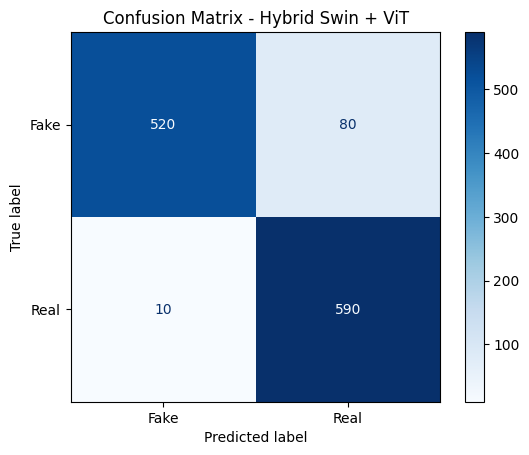

Accuracy:          92.50%
Precision:         93.09%
Recall/Sensitivity:92.50%
F1-Score:          92.47%


In [38]:
# =========================
# CLASSIFICATION METRICS
# =========================
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(
    all_labels, all_predictions,
    average="weighted", zero_division=0
)
recall = recall_score(
    all_labels, all_predictions,
    average="weighted", zero_division=0
)
f1 = f1_score(
    all_labels, all_predictions,
    average="weighted", zero_division=0
)

print("\nClassification Report:")
print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=test_dataset.classes,
        digits=4,
        zero_division=0
    )
)

cm = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize=(7, 6))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=test_dataset.classes
).plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Hybrid Swin + ViT")
plt.show()

print(f"Accuracy:          {accuracy*100:.2f}%")
print(f"Precision:         {precision*100:.2f}%")
print(f"Recall/Sensitivity:{recall*100:.2f}%")
print(f"F1-Score:          {f1*100:.2f}%")

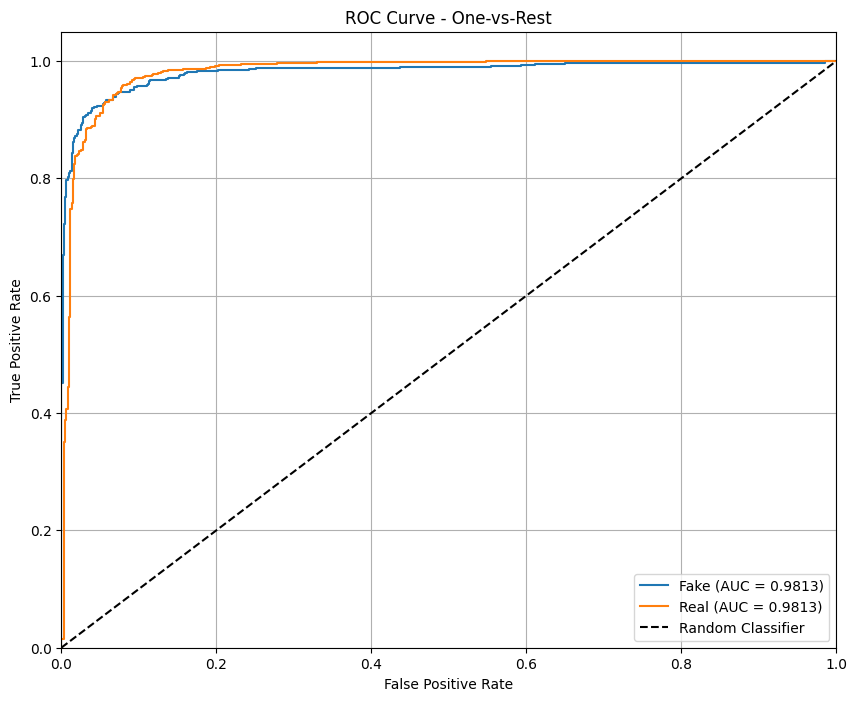

In [39]:
# =========================
# ROC-AUC CURVES
# =========================
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

all_probs = torch.softmax(
    torch.tensor(all_logits, dtype=torch.float32), dim=1
).numpy()

num_classes = len(test_dataset.classes)
all_labels_np = np.asarray(all_labels)

binarized_labels = np.zeros((len(all_labels_np), num_classes))
for i, label in enumerate(all_labels_np):
    binarized_labels[i, int(label)] = 1

fpr = {}
tpr = {}
roc_auc = {}

for i in range(num_classes):
    if len(np.unique(binarized_labels[:, i])) < 2:
        print(f"Skipping class {test_dataset.classes[i]}: only one label present.")
        continue

    fpr[i], tpr[i], _ = roc_curve(
        binarized_labels[:, i],
        all_probs[:, i]
    )
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure(figsize=(10, 8))
for i in roc_auc:
    plt.plot(
        fpr[i],
        tpr[i],
        label=f'{test_dataset.classes[i]} (AUC = {roc_auc[i]:.4f})'
    )

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - One-vs-Rest')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

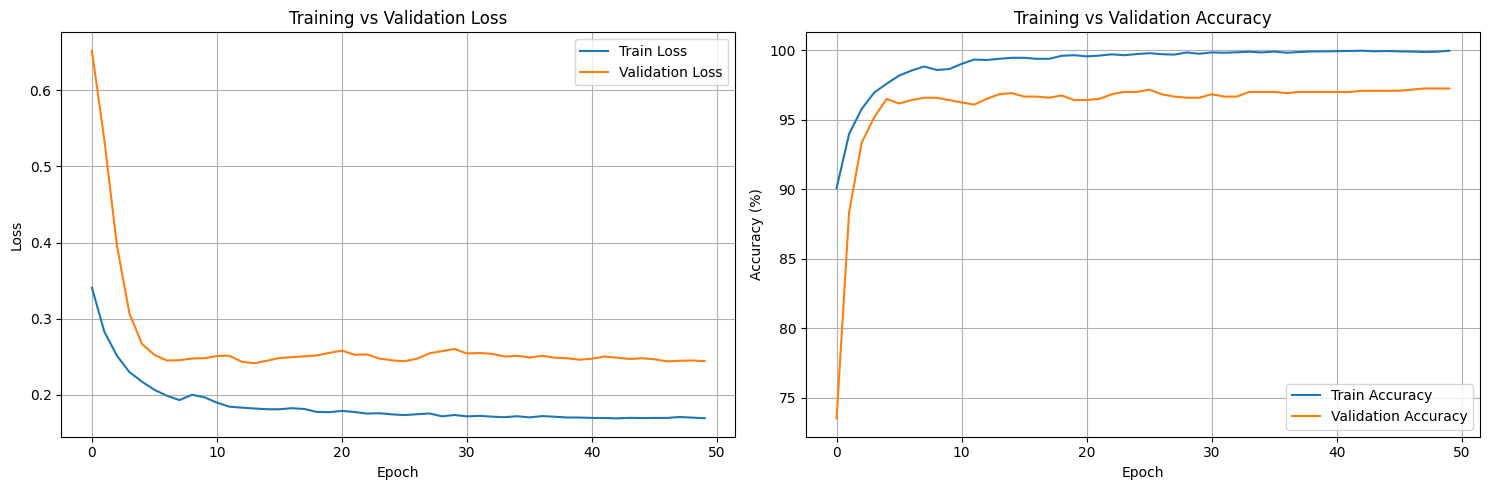

In [40]:
# =========================
# TRAINING CURVES
# =========================
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(history_hybrid["train_loss"], label="Train Loss")
axes[0].plot(history_hybrid["val_loss"], label="Validation Loss")
axes[0].set_title("Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    np.array(history_hybrid["train_acc"]) * 100,
    label="Train Accuracy"
)
axes[1].plot(
    np.array(history_hybrid["val_acc"]) * 100,
    label="Validation Accuracy"
)
axes[1].set_title("Training vs Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [41]:
# =========================
# SAVE BEST MODEL
# =========================
checkpoint = {
    "model_state_dict": hybrid_model.state_dict(),
    "class_names": train_dataset.classes,
    "img_size": IMG_SIZE,
    "best_val_accuracy": best_val_acc,
    "best_val_loss": best_val_loss
}

torch.save(checkpoint, "best_hybrid_model.pth")
print("Best hybrid model checkpoint saved as best_hybrid_model.pth")

Best hybrid model checkpoint saved as best_hybrid_model.pth


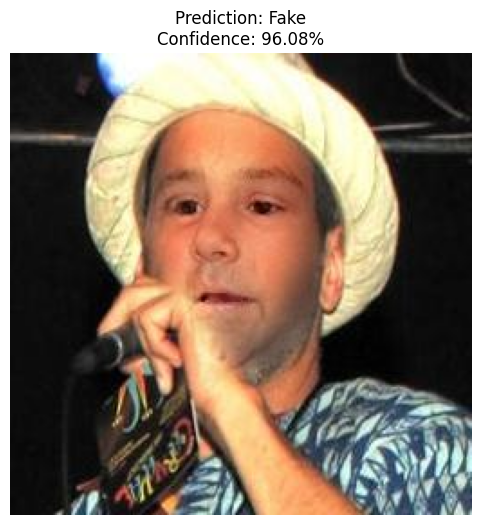

Prediction: Fake
Confidence: 96.08%
Output shape: torch.Size([1, 2])
Probabilities: [[0.96075064 0.03924931]]
Predicted index: 0


In [86]:
# =========================
# SINGLE IMAGE PREDICTION
# =========================
from PIL import Image
import torch
import matplotlib.pyplot as plt

image_to_predict = Image.open(random_img_path).convert("RGB")

input_tensor = val_test_transform(image_to_predict)
input_batch = input_tensor.unsqueeze(0).to(device)

hybrid_model.eval()

with torch.no_grad():
    output = hybrid_model(input_batch)
    probabilities = torch.softmax(output, dim=1)

predicted_class_idx = probabilities.argmax(dim=1).item()
predicted_class_label = test_dataset.classes[predicted_class_idx]
confidence = probabilities[0, predicted_class_idx].item() * 100

plt.figure(figsize=(6, 6))
plt.imshow(image_to_predict)
plt.title(
    f"Prediction: {predicted_class_label}\n"
    f"Confidence: {confidence:.2f}%"
)
plt.axis("off")
plt.show()

print(f"Prediction: {predicted_class_label}")
print(f"Confidence: {confidence:.2f}%")
print("Output shape:", output.shape)
print("Probabilities:", probabilities.cpu().numpy())
print("Predicted index:", predicted_class_idx)

## Explainable AI: evidence map




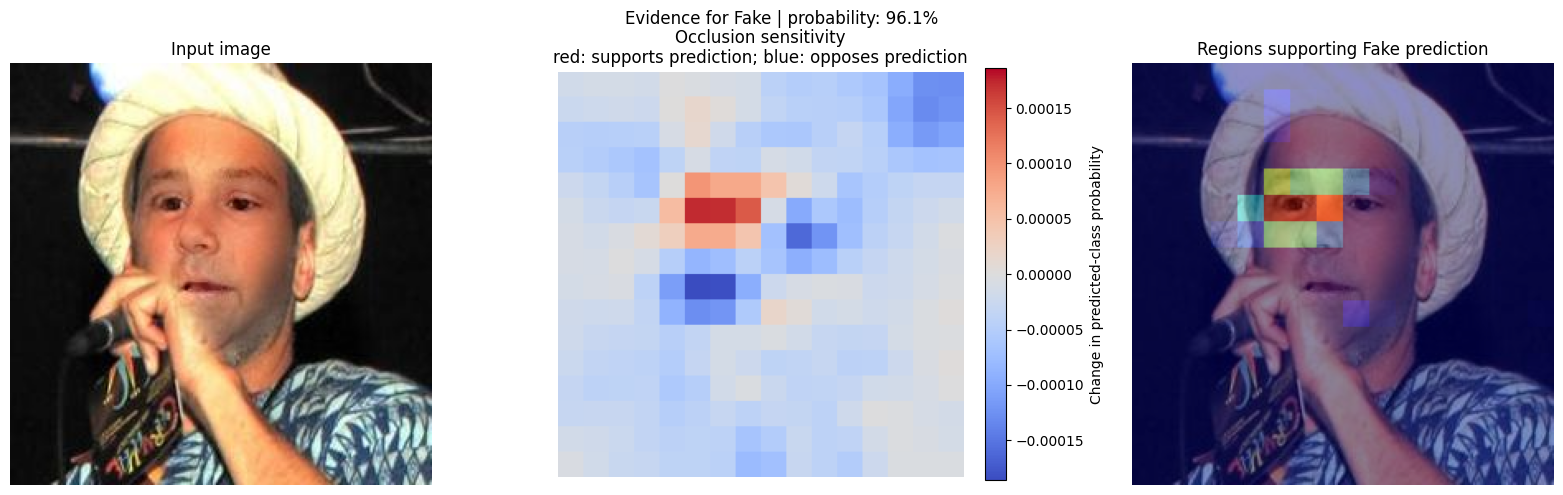

Explained prediction: Fake (96.1%)


In [87]:
# ============================================================
# XAI: OCCLUSION MAP FOR EVIDENCE SUPPORTING THE PREDICTED CLASS
# ============================================================
import numpy as np
import torch
import matplotlib.pyplot as plt


def explain_with_occlusion(model, image_pil, transform, device, class_index,
                           patch_size=32, stride=16, occlusion_batch_size=32):
    """Positive values support the target class; negative values oppose it.

    This image-level evidence map is not a pixel-level ground-truth mask.
    """
    model.eval()
    image_tensor = transform(image_pil).unsqueeze(0).to(device)
    height, width = image_tensor.shape[-2:]
    with torch.no_grad():
        original_prob = torch.softmax(model(image_tensor), dim=1)[0, class_index].item()

    ys = list(range(0, max(1, height - patch_size + 1), stride))
    xs = list(range(0, max(1, width - patch_size + 1), stride))
    if not ys or ys[-1] != height - patch_size:
        ys.append(max(0, height - patch_size))
    if not xs or xs[-1] != width - patch_size:
        xs.append(max(0, width - patch_size))
    locations = [(y, x) for y in ys for x in xs]

    patch_scores = []
    with torch.no_grad():
        for start in range(0, len(locations), occlusion_batch_size):
            batch_locations = locations[start:start + occlusion_batch_size]
            occluded = image_tensor.repeat(len(batch_locations), 1, 1, 1)
            for row, (y, x) in enumerate(batch_locations):
                # Zero in normalized space replaces the patch with mean color.
                occluded[row, :, y:y + patch_size, x:x + patch_size] = 0.0
            probs = torch.softmax(model(occluded), dim=1)[:, class_index]
            patch_scores.extend((original_prob - probs).cpu().tolist())

    heatmap = np.zeros((height, width), dtype=np.float32)
    counts = np.zeros((height, width), dtype=np.float32)
    for (y, x), score in zip(locations, patch_scores):
        heatmap[y:y + patch_size, x:x + patch_size] += score
        counts[y:y + patch_size, x:x + patch_size] += 1
    heatmap /= np.maximum(counts, 1)
    return original_prob, heatmap


def plot_class_evidence(image_pil, class_probability, heatmap, class_label):
    image_np = np.asarray(image_pil)
    positive = np.maximum(heatmap, 0)
    if positive.max() > 0:
        positive = positive / positive.max()
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    axes[0].imshow(image_np)
    axes[0].set_title("Input image")
    axes[0].axis("off")
    limit = max(float(np.max(np.abs(heatmap))), 1e-8)
    signed = axes[1].imshow(heatmap, cmap="coolwarm", vmin=-limit, vmax=limit)
    axes[1].set_title("Occlusion sensitivity\nred: supports prediction; blue: opposes prediction")
    axes[1].axis("off")
    fig.colorbar(signed, ax=axes[1], fraction=0.046, label="Change in predicted-class probability")
    axes[2].imshow(image_np)
    axes[2].imshow(positive, cmap="jet", alpha=0.45, vmin=0, vmax=1)
    axes[2].set_title(f"Regions supporting {class_label} prediction")
    axes[2].axis("off")
    fig.suptitle(f"Evidence for {class_label} | probability: {class_probability:.1%}")
    plt.tight_layout()
    plt.show()

# Select the model's predicted label (real or fake) and explain that class.
with torch.no_grad():
    prediction_logits = hybrid_model(input_batch)
    prediction_probabilities = torch.softmax(prediction_logits, dim=1)[0]
predicted_class_index = int(prediction_probabilities.argmax().item())
predicted_class_label = test_dataset.classes[predicted_class_index]
predicted_class_probability = float(prediction_probabilities[predicted_class_index].item())

class_probability, xai_heatmap = explain_with_occlusion(
    hybrid_model, image_to_predict, val_test_transform, device,
    class_index=predicted_class_index, patch_size=32, stride=16
)
plot_class_evidence(
    image_to_predict, class_probability, xai_heatmap, predicted_class_label
)
print(f"Explained prediction: {predicted_class_label} ({class_probability:.1%})")


## Cross-dataset evaluation scaffold
Place the independently sourced Deepfake-and-Real-images and Real-and-Fake-images-dataset-for-image-forensicstest images in class-folder structure matching the training class names, after documenting label mapping and any frame/image sampling. Do not fine-tune on these test sets for a zero-shot generalisation claim.


In [76]:

# ============================================
# FIXED CROSS-DATASET EVALUATION
# ============================================

from torchvision import datasets
from torch.utils.data import DataLoader
import os

DEEPFAKE_AND_REAL_IMAGES_TEST_DIR =  "/kaggle/input/datasets/manjilkarki/deepfake-and-real-images/Dataset/Test" 
REAL_AND_FAKE_IMAGES_DATASET1_TEST_DIR = "/kaggle/input/datasets/shivamardeshna/real-and-fake-images-dataset-for-image-forensics/Data Set 1/Data Set 1/test"

def make_external_loader(root, transform, batch_size=BATCH_SIZE):

    if root is None or not os.path.isdir(root):
        raise FileNotFoundError(f"Dataset directory not found: {root}")

    ds = datasets.ImageFolder(root, transform=transform)

    aliases = {
        "fake": "fake",
        "deepfake": "fake",
        "real": "real",
        "original": "real"
    }

    train_classes = {
        aliases.get(name.lower(), name.lower()): idx
        for name, idx in train_dataset.class_to_idx.items()
    }
    external_classes = {
        aliases.get(name.lower(), name.lower()): idx
        for name, idx in ds.class_to_idx.items()
    }

    # Verify that both datasets contain the same classes
    if set(train_classes.keys()) != set(external_classes.keys()):
        raise ValueError(
            f"Class mismatch!\n"
            f"Training classes: {list(train_classes.keys())}\n"
            f"External classes: {list(external_classes.keys())}"
        )

    # Map external labels to training label indices
    label_mapping = {
        external_idx: train_classes[class_name]
        for class_name, external_idx in external_classes.items()
    }

    ds.target_transform = lambda target: label_mapping[target]

    loader = DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available()
    )
    
    print("Dataset:", root)
    print("External classes:", ds.classes)
    print("Training classes:", train_dataset.classes)
    print("Label mapping:", label_mapping)
    print("Number of images:", len(ds))

    return ds, loader


def evaluate_external_dataset(model, root, dataset_name):

    ds, loader = make_external_loader(
        root,
        val_test_transform
    )

    model.eval()

    loss, acc = evaluate(
        model,
        loader,
        criterion,
        device
    )

    print("\n==========", dataset_name, "==========")
    print("Total images:", len(ds))
    print(f"Loss: {loss:.4f}")
    print(f"Accuracy: {acc * 100:.2f}%")

    return {
        
        "dataset": dataset_name,
        "images": len(ds),
        "loss": loss,
        "accuracy": acc
    }


# Run external evaluation
dfrealimg_result = evaluate_external_dataset(
    hybrid_model,
    DEEPFAKE_AND_REAL_IMAGES_TEST_DIR,
    "Deepfake-and-Real-images"
)

real_fake_result = evaluate_external_dataset(
    hybrid_model,
    REAL_AND_FAKE_IMAGES_DATASET1_TEST_DIR,
    "Real-and-Fake-images-dataset-for-image-forensics"
)



Dataset: /kaggle/input/datasets/manjilkarki/deepfake-and-real-images/Dataset/Test
External classes: ['Fake', 'Real']
Training classes: ['Fake', 'Real']
Label mapping: {0: 0, 1: 1}
Number of images: 10905

========== Deepfake-and-Real-images ==========
Total images: 10905
Loss: 0.3173
Accuracy: 94.12%
Dataset: /kaggle/input/datasets/shivamardeshna/real-and-fake-images-dataset-for-image-forensics/Data Set 1/Data Set 1/test
External classes: ['fake', 'real']
Training classes: ['Fake', 'Real']
Label mapping: {0: 0, 1: 1}
Number of images: 5227

========== Real-and-Fake-images-dataset-for-image-forensics ==========
Total images: 5227
Loss: 0.3984
Accuracy: 90.86%
